<a href="https://colab.research.google.com/github/AmeerHamzaIlyas/ML-Hundred-Feature_Enginering/blob/main/ML_100(Feature_Enginering_02_Normalization).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Normalization --> To change the values range into a suitable scale that not lose the information of the dataset.
 # Types of normalization
 1. min-max scalling
 2. mean normalization
 3. max-absolute scalling
 4. Robust scalling

# 1.Min-Max Scalling
Formula :
  x(i)` = x(i) - x(min) / x(max) -x(min)

  min-max range : [0,1]
  standardscale range : [-1,+1]
  mean-normalization range : [-1,+1]
  

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/wine_normalization_practice.csv")
df

,alcohol,malic_acid,class_label
0,14.23,1.71,0
1,13.20,1.78,0
2,13.16,2.36,0
3,14.37,1.95,0
4,13.24,2.59,0
...,...,...,...
173,13.71,5.65,2
174,13.40,3.91,2
175,13.27,4.28,2
176,13.17,2.59,2


KDE (Kernal Density Distribution) plot --> for contineous numerical values distribution

<Axes: xlabel='alcohol', ylabel='Density'>

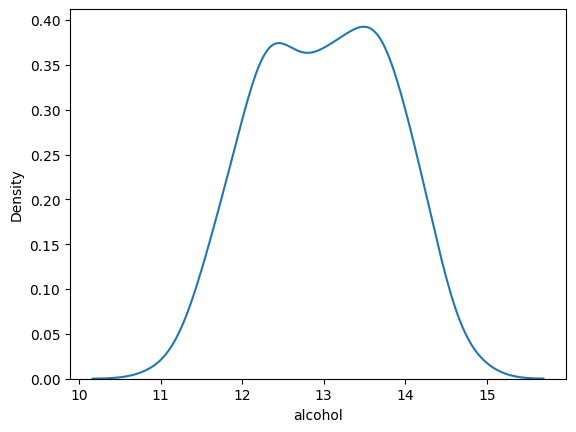

In [ ]:
sns.kdeplot(df['alcohol'])

<Axes: xlabel='malic_acid', ylabel='Density'>

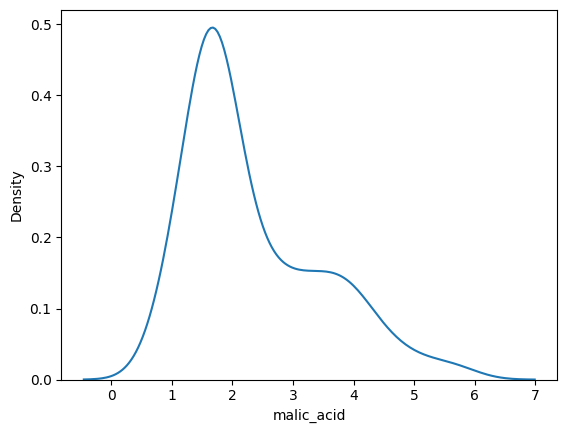

In [ ]:
sns.kdeplot(df['malic_acid'])

<Axes: xlabel='alcohol', ylabel='malic_acid'>

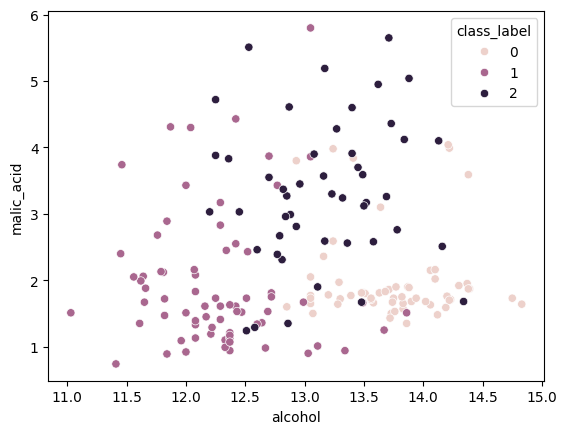

In [ ]:
sns.scatterplot(data=df,x=df["alcohol"],y=df["malic_acid"],hue=df["class_label"])

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop(["class_label"],axis=1),df["class_label"],test_size=0.2,random_state=42)


In [ ]:
X_train.shape

(142, 2)

In [ ]:
X_test.shape

(36, 2)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(X_train)

MinMaxScaler()

In [ ]:
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

In [ ]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)



In [ ]:
# X_train_scaled

In [ ]:
# convert array to dataframe
X_train_scaled = pd.DataFrame(X_train_scaled,columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled,columns=X_test.columns)

In [ ]:
X_train_scaled

,alcohol,malic_acid
0,0.871053,0.160896
1,0.394737,0.940937
2,0.352632,0.036660
3,0.644737,0.158859
4,0.536842,0.124236
...,...,...
137,0.744737,0.126273
138,0.321053,0.171079
139,0.881579,0.199593
140,0.436842,0.130346


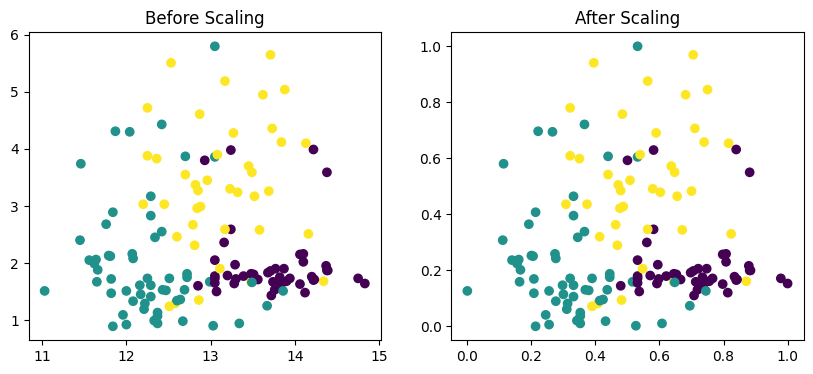

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.scatter(X_train["alcohol"], X_train["malic_acid"], c=y_train)
ax2.scatter(X_train_scaled["alcohol"], X_train_scaled["malic_acid"], c=y_train)
ax1.set_title("Before Scaling")
ax2.set_title("After Scaling")
plt.show()

# 2. Mean Normalization
 Formula  X(i) = x(i)` - x(mean) / x(max) - x(min)
  mean-normalization range : [-1,+1]

useful foe centered data (but mostly use standard-scaller)

# 3. Max-Absolute Scaler
 Formula X(i)` = x(i) / |x(max)|
 1. useful for sparse data (which contains more zeros)
 2. sklearn class maxabsscaler

# 4. Robust scaling
Formula x(i)` = x(i) - x(median) / IQR (inter-quartile-range)

1. sklearn class robustscaller
2. suitable for outliers
